In [29]:
import rasterio
from rasterio.merge import merge
import numpy as np
import glob
import os
from scipy.optimize import curve_fit
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import xarray as xr

## load in the data
# directory_path = 'H:/My Drive/NDVI_Exports/DLCTemp'
directory_path = 'H:/My Drive/DroughtSurfing/WY/tmp'

## list of file paths for each year's raster
yearly_files = sorted(glob.glob(os.path.join(directory_path, '*.tif')))

## list to store the opened raster files
raster_data = []
shapes = []
all_dates = [] 

for file in yearly_files:
    with rasterio.open(file) as src:
        print(f"Reading file: {file}")
        print(f"Shape: {src.shape}")
        print(f"Number of Bands: {src.count}")
        print(f"CRS: {src.crs}")
        print(f"Transform: {src.transform}")
        print(f"Data type: {src.dtypes[0]}")
        print()

        ## read all bands of the raster data
        data = src.read()  # reading all bands
        raster_data.append(data)
        shapes.append(data.shape)

        if src.descriptions:
            file_dates = pd.to_datetime(
                [desc.split('_NDVI')[0] for desc in src.descriptions if '_NDVI' in desc], 
                format='%Y_%m_%d'
            )
            all_dates.extend(file_dates)
        else:
            print(f"No band descriptions found in {file}, skipping date extraction.")


## find the maximum dimensions
max_shape = np.max([data.shape[1:] for data in raster_data], axis=0)  # rows, cols
print("Max Shape (rows, cols):", max_shape)

## initialize list for all bands combined
combined_raster_data = []

## pad each array to the maximum shape
for idx, data in enumerate(raster_data):
    for band in range(data.shape[0]):
        padded = np.pad(data[band], 
                        ((0, max_shape[0] - data.shape[1]),  # pad rows
                         (0, max_shape[1] - data.shape[2])),  # pad columns
                        mode='constant', constant_values=np.nan)
        combined_raster_data.append(padded)
        print(f"Original Shape for file {idx}, band {band}: {data[band].shape}")
        print(f"Padded Shape for file {idx}, band {band}: {padded.shape}")

## convert to numpy array
stacked_data = np.stack(combined_raster_data, axis=0)

## check shape and data to confirm
print("Stacked Data Shape (total bands, rows, columns):", stacked_data.shape)

## check the dates
dates = pd.DatetimeIndex(all_dates)
print("Extracted Dates:", dates)


Reading file: H:/My Drive/DroughtSurfing/WY/tmp\smoothed_ndvi_2017_chunk_0.tif
Shape: (752, 958)
Number of Bands: 5
CRS: EPSG:4326
Transform: | 0.00, 0.00,-110.80|
| 0.00,-0.00, 43.41|
| 0.00, 0.00, 1.00|
Data type: float32

Reading file: H:/My Drive/DroughtSurfing/WY/tmp\smoothed_ndvi_2017_chunk_1.tif
Shape: (752, 958)
Number of Bands: 5
CRS: EPSG:4326
Transform: | 0.00, 0.00,-110.80|
| 0.00,-0.00, 43.41|
| 0.00, 0.00, 1.00|
Data type: float32

Reading file: H:/My Drive/DroughtSurfing/WY/tmp\smoothed_ndvi_2017_chunk_2.tif
Shape: (752, 958)
Number of Bands: 5
CRS: EPSG:4326
Transform: | 0.00, 0.00,-110.80|
| 0.00,-0.00, 43.41|
| 0.00, 0.00, 1.00|
Data type: float32

Reading file: H:/My Drive/DroughtSurfing/WY/tmp\smoothed_ndvi_2017_chunk_3.tif
Shape: (752, 958)
Number of Bands: 5
CRS: EPSG:4326
Transform: | 0.00, 0.00,-110.80|
| 0.00,-0.00, 43.41|
| 0.00, 0.00, 1.00|
Data type: float32

Reading file: H:/My Drive/DroughtSurfing/WY/tmp\smoothed_ndvi_2017_chunk_4.tif
Shape: (752, 958)
Num

In [17]:
## calculate min and max along the stack (axis 0)
min_val = np.nanmin(stacked_data, axis=0)
max_975_quantile = np.nanquantile(stacked_data, 0.975, axis=0)

## avoid division by zero by adding a small epsilon value
epsilon = 1e-10
denominator = max_975_quantile - min_val + epsilon

## get the scaled data of the raster stack
scaled_data = (stacked_data - min_val) / denominator

## check the scaled data values to confirm
print("Min Values:", min_val)
print("Max 97.5th Percentile Values:", max_975_quantile)
print("Scaled Data:", scaled_data)

## optional: check the shape of the scaled_data to confirm
print("Scaled Data Shape:", scaled_data.shape) # bands, rows, columns


C:\Users\tlasharr\AppData\Local\Temp\ipykernel_15752\758882183.py:2: RuntimeWarning: All-NaN slice encountered
  min_val = np.nanmin(stacked_data, axis=0)
c:\Users\tlasharr\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


Min Values: [[        nan  0.5554985   0.5503919  ... -0.02443078 -0.02936491
  -0.02908318]
 [ 0.42512178  0.4125261   0.4125261  ... -0.0241833  -0.0241833
  -0.01989566]
 [        nan         nan  0.3629361  ... -0.02111959 -0.01838736
  -0.01550922]
 ...
 [-0.06184557 -0.05532029 -0.06255666 ... -0.01526793 -0.01520007
  -0.02042099]
 [-0.06303172 -0.06303172 -0.06375271 ... -0.0215327  -0.02225313
  -0.02225313]
 [-0.04128373 -0.047034   -0.07318862 ... -0.02512389 -0.02512389
  -0.02956419]]
Max 97.5th Percentile Values: [[       nan 0.72112167 0.75876504 ... 0.26892543 0.251735   0.26643598]
 [0.7759764  0.7794713  0.7794713  ... 0.32639042 0.32639042 0.2824579 ]
 [       nan        nan 0.7476517  ... 0.2920635  0.36708102 0.4112813 ]
 ...
 [0.45815292 0.44674954 0.435052   ... 0.1725964  0.17315136 0.15061331]
 [0.49189624 0.49189624 0.5021978  ... 0.14412947 0.15607661 0.15607661]
 [0.70091975 0.6260809  0.50883096 ... 0.16917221 0.16917221 0.22066848]]
Scaled Data: [[[       

In [ ]:
## define the DLC model

def dlc_model(time, xmidS, scalS, xmidA, scalA):
    return (1 / (1 + np.exp((xmidS - time) / scalS))) - (1 / (1 + np.exp((xmidA - time) / scalA)))


In [ ]:
years = [2017, 2018]

## get the dates
dates = []
for year in years:
    start_date = datetime(year, 1, 1)
    dates.extend([start_date + timedelta(days=8 * i) for i in range(46)])  # 46 intervals in 365-day year

dates = pd.to_datetime(dates)

## intial parameters to try for the DLC
dlc_bounds = ([30, 1, 167, 1], [228, 30, 288, 35])

## run the function for each pixel seperately
def fit_dlc_per_pixel(ndvi_data, time, dlc_bounds):
    if np.isnan(ndvi_data).any() or len(ndvi_data[~np.isnan(ndvi_data)]) < 4:
        return [np.nan] * 8  # return NaNs if insufficient data

    try:
        ## initial parameter guesses
        initial_guess = [130, 10, 230, 17]
        
        ## perform the curve fitting
        popt, pcov = curve_fit(dlc_model, time, ndvi_data, p0=initial_guess, bounds=dlc_bounds)
        
        ## extract standard errors from the covariance matrix
        perr = np.sqrt(np.diag(pcov))
        
        ## return parameters and standard errors
        return list(popt) + list(perr)
    
    except Exception as e:
        print(f"Error fitting pixel: {e}")
        return [np.nan] * 8

## process the data for each year seperately
def fit_dlc_for_year(ndvi_stack, dates, years, dlc_bounds):
    results = []
    
    for year in years:
        # Subset NDVI data to current year
        year_indices = [i for i, date in enumerate(dates) if date.year == year]
        ndvi_year = ndvi_stack[year_indices]
        time = np.array([date.timetuple().tm_yday for i, date in enumerate(dates) if date.year == year])
        
        # Initialize result array for current year
        dlc_params = np.full((*ndvi_year.shape[1:], 8), np.nan)
        
        # Loop over each pixel
        for row in range(ndvi_year.shape[1]):
            for col in range(ndvi_year.shape[2]):
                ndvi_pixel = ndvi_year[:, row, col]
                dlc_params[row, col, :] = fit_dlc_per_pixel(ndvi_pixel, time, dlc_bounds)
                
        results.append(dlc_params)
    
    return np.stack(results, axis=0)  # Shape: (years, rows, cols, params)


## fit the DLC model for each year
dlc_results = fit_dlc_for_year(stacked_data, dates, years, dlc_bounds)

print("DLC Parameters Shape:", dlc_results.shape) ## years, 

Error fitting pixel: Optimal parameters not found: The maximum number of function evaluations is exceeded.
Error fitting pixel: Optimal parameters not found: The maximum number of function evaluations is exceeded.
Error fitting pixel: Optimal parameters not found: The maximum number of function evaluations is exceeded.
DLC Parameters Shape: (2, 752, 958, 8)


In [ ]:

# Function to calculate fitted NDVI values for each pixel based on the DLC parameters
def calculate_fitted_vals(dlc_params, dates, values="daily"):
    time = np.arange(1, 366) if values == "daily" else np.arange(1, 366, 7)
    fitted_vals = np.full((dlc_params.shape[0], dlc_params.shape[1], len(time)), np.nan)
    
    for row in range(dlc_params.shape[0]):
        for col in range(dlc_params.shape[1]):
            params = dlc_params[row, col, :4]
            if np.isnan(params).any():
                continue  # Skip pixels with NaN parameters
            fitted_vals[row, col, :] = dlc_model(time, *params)
    
    return fitted_vals

# Function to calculate Instantaneous Rate of Green-up (IRG)
def calculate_irg(fitted_vals, sclIRG=True):
    # Calculate the difference along the time dimension (axis=2)
    irg = np.diff(fitted_vals, axis=2)
    
    # Pad the last day with NaN to keep the dimensions consistent
    irg = np.concatenate((irg, np.full(irg.shape[:-1] + (1,), np.nan)), axis=2)
    
    # Set negative IRG values to 0
    irg[irg < 0] = 0
    
    # Scale IRG values between 0 and 1 if required
    if sclIRG:
        irg_min = np.nanmin(irg)
        irg_max = np.nanmax(irg)
        if irg_max > irg_min:  # Prevent division by zero
            irg = (irg - irg_min) / (irg_max - irg_min)
    
    return irg


# Function to calculate max values and peak dates, with handling for all-NaN slices
def calculate_max_and_dates(values_array, time_points, func="max"):
    # Initialize arrays to hold results, filled with NaNs initially
    max_vals = np.full(values_array.shape[:2], np.nan)
    max_dates = np.full(values_array.shape[:2], np.nan)

    for row in range(values_array.shape[0]):
        for col in range(values_array.shape[1]):
            pixel_values = values_array[row, col, :]
            if np.isnan(pixel_values).all():
                continue  # Skip if all values are NaN for this pixel
            
            # Calculate max value and corresponding date
            max_vals[row, col] = np.nanmax(pixel_values)
            max_dates[row, col] = time_points[np.nanargmax(pixel_values)]
    
    return max_vals, max_dates

# Prepare time indices for date calculations
years = [2017, 2018]
dates = []
for year in years:
    start_date = datetime(year, 1, 1)
    dates.extend([start_date + timedelta(days=8 * i) for i in range(46)])  # 46 intervals in 365-day year
dates = pd.to_datetime(dates)

# Calculate fitted values and IRG for year 2017
time_points = np.arange(1, 366)  # Day of year for daily calculations
fitted_vals = calculate_fitted_vals(dlc_results[0, :, :, :], dates)  # for year 1, e.g., 2017
irg_vals = calculate_irg(fitted_vals)

# Calculate max values and dates
max_ndvi, max_ndvi_date = calculate_max_and_dates(fitted_vals, time_points, func="max")
max_irg, max_irg_date = calculate_max_and_dates(irg_vals, time_points, func="max")

print("Max NDVI Value:", max_ndvi)
print("Max NDVI date:", max_ndvi_date)

print("Max IRG Value:", max_irg)
print("Max IRG Date:", max_irg_date)



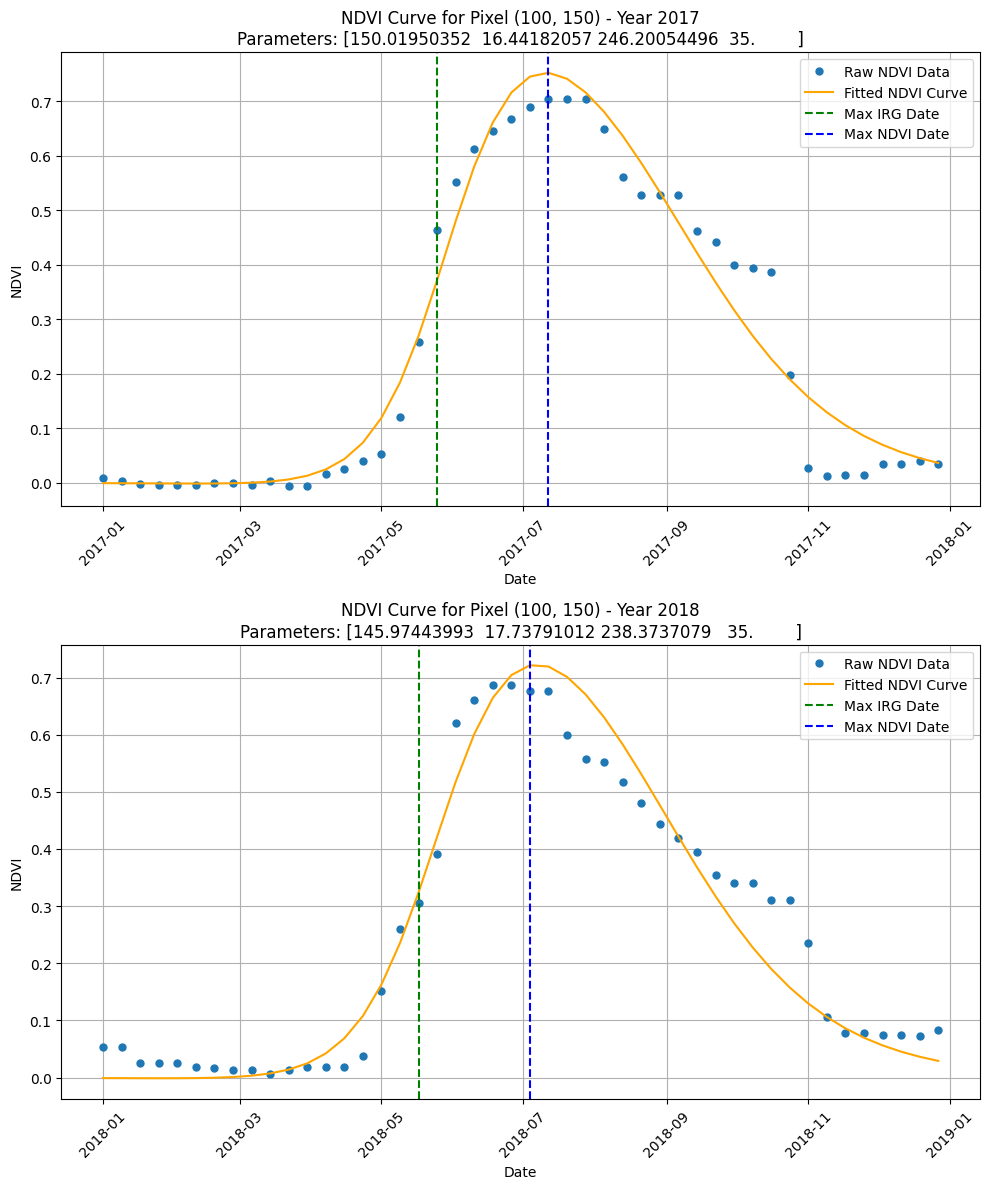

In [36]:
# Function to calculate fitted NDVI values for specific dates (8-day intervals) based on DLC parameters
def calculate_fitted_ndvi(dlc_params, time_points):
    return dlc_model(time_points, *dlc_params)

# Updated function to plot fitted and raw NDVI data with lines for max IRG and NDVI dates
def plot_ndvi_pixel(dlc_results, stacked_data, dates, row, col):
    fig, ax = plt.subplots(len(years), 1, figsize=(10, 6 * len(years)))
    
    if len(years) == 1:
        ax = [ax]  # Ensure ax is always a list for easy indexing when there's only one subplot
    
    for i, year in enumerate(years):
        ## Extract parameters for the current year and pixel
        params = dlc_results[i, row, col, :4]  # First 4 values are the fitted parameters
        
        ## Get the dates and time points for 8-day intervals
        year_dates = np.array([date for date in dates if date.year == year])
        time_points = np.array([date.timetuple().tm_yday for date in year_dates])
        
        ## Generate fitted curve if parameters are valid
        if not np.isnan(params).any():
            fitted_curve = calculate_fitted_ndvi(params, time_points)
            
            # Calculate IRG and find max dates (for 8-day intervals)
            irg_vals = np.diff(fitted_curve)
            max_irg_idx = np.nanargmax(irg_vals)
            max_ndvi_idx = np.nanargmax(fitted_curve)
            
            max_irg_date = year_dates[max_irg_idx]
            max_ndvi_date = year_dates[max_ndvi_idx]
        else:
            fitted_curve = None
            max_irg_date = max_ndvi_date = None
            print(f"No valid parameters for pixel ({row}, {col}) in {year}")
        
        ## Extract raw NDVI values for the current year and pixel
        year_indices = [j for j, date in enumerate(dates) if date.year == year]
        ndvi_values = stacked_data[year_indices, row, col]
        
        ## Plot raw NDVI data
        ax[i].plot(year_dates, ndvi_values, 'o', label="Raw NDVI Data", linestyle='None', markersize=5)
        
        ## Plot fitted DLC curve if available
        if fitted_curve is not None:
            ax[i].plot(year_dates, fitted_curve, label="Fitted NDVI Curve", color='orange')
            ax[i].set_title(f"NDVI Curve for Pixel ({row}, {col}) - Year {year}\nParameters: {params}")
            
            ## Plot vertical lines at max IRG and max NDVI dates
            if max_irg_date is not None:
                ax[i].axvline(max_irg_date, color='green', linestyle='--', label="Max IRG Date")
            if max_ndvi_date is not None:
                ax[i].axvline(max_ndvi_date, color='blue', linestyle='--', label="Max NDVI Date")
        else:
            ax[i].set_title(f"NDVI Curve for Pixel ({row}, {col}) - Year {year} (No Fit)")
        
        ## Formatting
        ax[i].set_xlabel("Date")
        ax[i].set_ylabel("NDVI")
        ax[i].legend()
        ax[i].grid(True)
        ax[i].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

## Specify row and column indices for the pixel you want to analyze
row_index = 100 
col_index = 150  

## Plot the raw and fitted NDVI data for the specified pixel across years
plot_ndvi_pixel(dlc_results, stacked_data, dates, row_index, col_index)
